# Pretraining datasets: EDA
Shape of each pretraining source and a common model input format.

| Dataset | Species | Slide | Recording | Section |
|---|---|---|---|---|
| IBL | mouse | 801 sessions, 251 mice, 1023 h | Neuropixels, spike-sorted units | §1, ONE API |
| Allen | mouse | 49 sessions, 4 mice, 134 h | Neuropixels, spike-sorted units | §2, Allen API, small subset |
| Gesture | human | 8 sessions, 2 humans, 1.7 h | Utah arrays | not local |
| Brain-to-Text '24 | human | 63 sessions, 18.8 h | Utah arrays | not local |
| Brain-to-Text '25 | human | 45 sessions, 39.2 h | Utah arrays, 512 features at 20 ms | §3, local (format reference) |

- The sroth pretraining pipeline reads only B2T '25 (`data/hdf5_data_final`). IBL and Allen are downloaded into `../data/{ibl,allen}`.
- Loaders: `src/neural_data.py`. Every source → `spike_times`, `spike_units` → counts `[T, N]` at 20 ms.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from neural_data import *  # src/ is on the .venv-train path
from viz import raster     # interactive plotly rasters

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.precision', 2)

## 1. IBL: Brain-Wide Map (mouse)
- Neuropixels probes (≤ 2 per session) during a visual decision task (`ephysChoiceWorld`).
- Spike sorting: pykilosort.
- Catalogue from the ONE cache tables, with no spikes downloaded.

In [2]:
one = ibl_one()  # public shared account (being retired: register your own at openalyx /signup)
probes = ibl_probe_table(one)
bwm = probes[probes.projects.str.contains('brainwide', na=False)]

def catalogue(p):
    return [p.eid.nunique(), len(p), p.subject.nunique(), p.lab.nunique(), p.spikes_times_mb.sum() / 1e3]
pd.DataFrame({'all public': catalogue(probes), 'brain-wide map': catalogue(bwm)},
             index=['sessions', 'probes', 'mice', 'labs', 'spikes.times total GB']).round(1)

,all public,brain-wide map
sessions,704.0,479.0
probes,1137.0,719.0
mice,219.0,148.0
labs,12.0,12.0
spikes.times total GB,79.4,58.7


- Public spike-sorted catalogue: 704 sessions / 219 mice, vs. 801 / 251 on the slide (other sorters or a newer release).
- spikes.times file size ≈ spike count × 8 B.

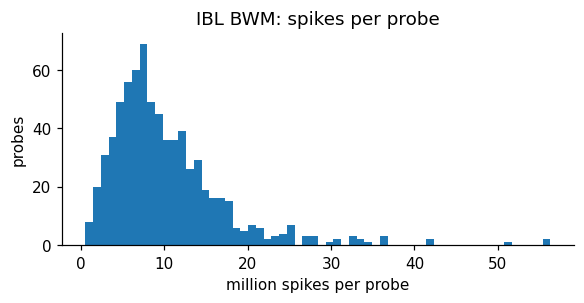

In [3]:
fig, ax = plt.subplots(figsize=(6, 2.5))
ax.hist(bwm.spikes_times_mb / 8, bins=60)  # MB / 8 B = million spikes
ax.set(xlabel='million spikes per probe', ylabel='probes', title='IBL BWM: spikes per probe')
plt.show()

### One probe
- Small BWM probe (DY_013, ~110 MB), cached in `../data/ibl`.

In [4]:
EID, PROBE = 'e535fb62-e245-4a48-b119-88ce62a6fe67', 'probe01'  # DY_013, danlab, 2020-03-12
ibl = load_ibl_probe(one, EID, PROBE)

summary = session_summary(f'IBL {PROBE}', ibl['spike_times'], ibl['spike_units'], ibl['n_units'])
summary['n_units_all'] = len(ibl['all_units'])
summary['n_trials'] = len(ibl['trials'])
pd.Series(summary)

session         IBL probe01
n_units                  39
n_spikes             811753
duration_min          63.79
n_bins_20ms          191381
mean_rate_hz           5.44
n_units_all             464
n_trials                434
dtype: object

### What counts as a "good" unit (IBL)
Each sorted cluster gets three pass/fail tests. `label` = fraction passed (0, ⅓, ⅔, 1); **good = `label == 1`**.
1. **Refractory period**: almost no spikes closer together than a neuron can fire (`slidingRP_viol == 1`). The cluster is one neuron, not a mixture.
2. **Noise cutoff**: the amplitude distribution isn't cut off by the detection threshold (`noise_cutoff < 5`), so few spikes are missed.
3. **Amplitude**: median spike amplitude > 50 µV (`amp_median`), clearly above background noise.

This probe: 464 clusters → 155 pass test 1 → 41 pass tests 1–2 → **39 pass all three (8%)**.
- Good only: clean, small N. All clusters: more data, including multi-unit activity.

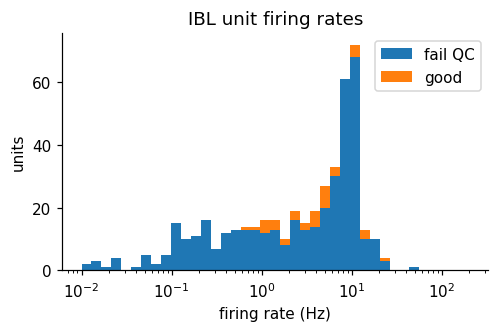

In [5]:
fig, ax = plt.subplots(figsize=(5, 2.8))
fr = ibl['all_units']['firing_rate']
ax.hist([fr[ibl['all_units'].label < 1], fr[ibl['all_units'].label == 1]], bins=np.logspace(-2, 2.3, 40),
        stacked=True, label=['fail QC', 'good'])
ax.set(xscale='log', xlabel='firing rate (Hz)', ylabel='units', title='IBL unit firing rates'); ax.legend()
plt.show()

### Raster
- Red lines mark stimulus onsets. 
- Showing the first 5 min only.

In [6]:
raster(ibl['spike_times'], ibl['spike_units'], 0, 300,
       events={'stim on': ibl['trials']['stimOn_times'].dropna().to_numpy()},
       title='IBL good units, first 5 min')

### Behaviour (trials table)
- One row per trial: stimulus contrast (left/right), choice, feedback, event times.
- Candidate labels for downstream decoding.

In [7]:
cols = ['stimOn_times', 'contrastLeft', 'contrastRight', 'probabilityLeft', 'choice', 'feedbackType', 'response_times', 'firstMovement_times']
ibl['trials'][cols].head()

,stimOn_times,contrastLeft,contrastRight,probabilityLeft,choice,feedbackType,response_times,firstMovement_times
0,11.28,NaN,0.25,0.5,-1.0,1.0,11.72,11.52
1,14.20,1.0,NaN,0.5,1.0,1.0,14.39,14.12
2,17.01,1.0,NaN,0.5,1.0,1.0,23.22,17.49
3,25.86,NaN,1.00,0.5,-1.0,1.0,26.09,25.96
4,30.92,NaN,0.06,0.5,-1.0,1.0,31.15,31.00


### Binned → trial-aligned tensor
- Continuous `[T, N]` at 20 ms.
- Windows around stimulus onset (−0.5 s … +1 s) → `[n_trials, 75, N]`.

continuous (191383, 39) uint16 | trial-aligned (434, 75, 39) | sparsity 90.4% zeros


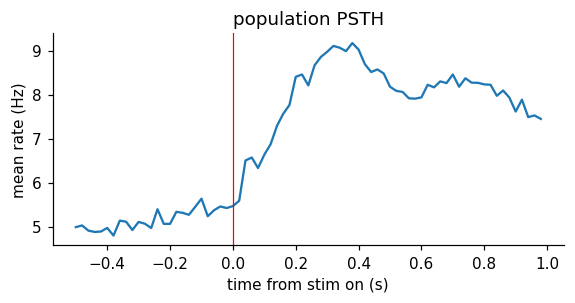

In [8]:
X_ibl = bin_spikes(ibl['spike_times'], ibl['spike_units'], ibl['n_units'], t_start=0)
on = (ibl['trials']['stimOn_times'].dropna().to_numpy() / BIN_SIZE).astype(int)
PRE, POST = 25, 50
on = on[(on - PRE >= 0) & (on + POST <= len(X_ibl))]
trials_ibl = np.stack([X_ibl[i - PRE:i + POST] for i in on])
print('continuous', X_ibl.shape, X_ibl.dtype, '| trial-aligned', trials_ibl.shape, '| sparsity', f'{(X_ibl == 0).mean():.1%} zeros')

fig, ax = plt.subplots(figsize=(6, 2.5))
t = (np.arange(-PRE, POST)) * BIN_SIZE
ax.plot(t, trials_ibl.mean((0, 2)) / BIN_SIZE); ax.axvline(0, c='r', lw=0.8)
ax.set(xlabel='time from stim on (s)', ylabel='mean rate (Hz)', title='population PSTH')
plt.show()

## 2. Allen: Visual Coding Neuropixels (mouse)
- Source: Allen API (`api.brain-map.org`, models `EcephysSession` / `EcephysUnit`). Session and unit metadata come without downloading spikes; spikes are streamed from the session NWB.
- 58 sessions, one mouse each. Passive viewing with no task. 6 probes across visual cortex, thalamus and hippocampus.
- The slide's exact Allen release is unconfirmed; this is a representative Allen spiking set.

### Pretraining subset (`scripts/download_mouse_data.py --dataset allen`)
- **Sessions:** the 3 Brain Observatory 1.1 sessions with the most good units.
- **Units:** `quality == 'good'`.
- **Time:** spontaneous + natural movies (~51 of ~160 min): continuous, naturalistic viewing. Gratings, gabors, flashes and scenes are dropped.
- **Storage:** spike times (float32) + unit ids (uint16), 65–77 MB per session.

### What counts as a "good" unit (Allen)
1. **Noise classifier**: an automated classifier labels clusters with a non-neural waveform shape or spatial footprint as `noise`. Everything else is `quality == 'good'`. This is the only filter applied in the subset.
2. **Stricter metrics** (AllenSDK default filter), *not* applied here:
   - ISI violations < 0.5: refractory-period contamination.
   - Amplitude cutoff < 0.1: fraction of spikes missed by the threshold.
   - Presence ratio > 0.9: unit present for ≥ 90% of the session.

ses-732592105: 3018 clusters → **2766 good** (noise removed) → 1759 → 1011 → 850 with all three metrics.
- Allen `good` is much looser than IBL `good`. IBL-like strictness would keep ~30% of these units.

In [9]:
sessions = allen_sessions()
print(len(sessions), 'sessions,', sessions.specimen_id.nunique(), 'mice |', sessions.stimulus_name.value_counts().to_dict())
units_tab = allen_session_units_table()  # good units per BO 1.1 session, from the API (cached csv)
units_tab.describe().loc[['mean', 'min', '50%', 'max'], ['n_good_units', 'n_visual_cortex', 'n_areas']].round(0)

58 sessions, 58 mice | {'brain_observatory_1.1': 32, 'functional_connectivity': 26}


,n_good_units,n_visual_cortex,n_areas
mean,1693.0,664.0,16.0
min,1191.0,396.0,6.0
50%,1672.0,684.0,17.0
max,2766.0,947.0,23.0


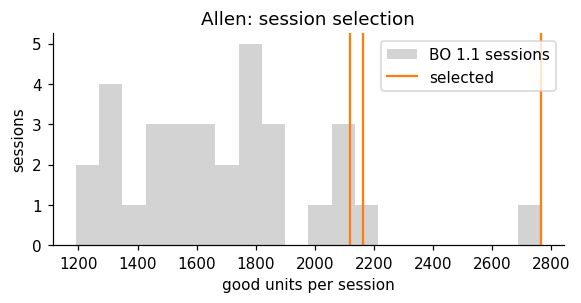

In [10]:
SELECTED = units_tab.session_id.head(3).tolist()
fig, ax = plt.subplots(figsize=(6, 2.5))
ax.hist(units_tab.n_good_units, bins=20, color='lightgray', label='BO 1.1 sessions')
for i, sid in enumerate(SELECTED):
    ax.axvline(units_tab.set_index('session_id').n_good_units[sid], c='C1', label='selected' if i == 0 else None)
ax.set(xlabel='good units per session', ylabel='sessions', title='Allen: session selection'); ax.legend()
plt.show()

In [11]:
allen_subsets = {sid: load_allen_subset(sid) for sid in SELECTED}
def subset_row(sid, s):
    minutes = (s['epochs'].stop - s['epochs'].start).sum() / 60
    return {'n_units': s['n_units'], 'n_spikes': len(s['spike_times']), 'minutes': minutes,
            'mean_rate_hz': len(s['spike_times']) / (minutes * 60) / s['n_units'], 'n_areas': s['units'].area.nunique()}
pd.DataFrame({f'ses-{sid}': subset_row(sid, s) for sid, s in allen_subsets.items()}).T

,n_units,n_spikes,minutes,mean_rate_hz,n_areas
ses-732592105,2766.0,3.67e+07,50.65,4.37,7.0
ses-742951821,2165.0,3.01e+07,50.64,4.58,8.0
ses-750332458,2120.0,3.55e+07,50.64,5.52,14.0


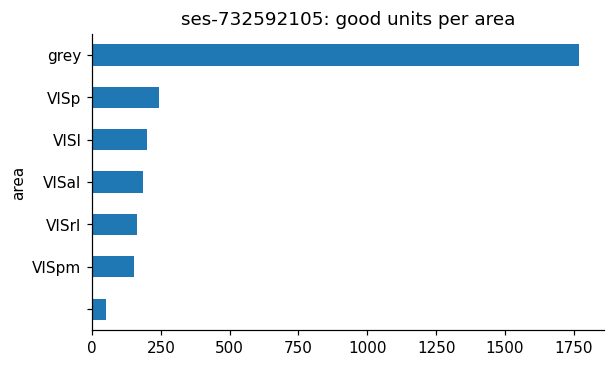

,stimulus,start,stop
0,spontaneous,21.58,81.65
1,spontaneous,993.64,1282.63
2,spontaneous,1581.13,1582.88
3,spontaneous,2182.38,3174.25
4,spontaneous,3773.76,4705.66
5,spontaneous,5389.26,5390.26
6,spontaneous,5870.67,5900.69
7,spontaneous,6381.09,6681.34
8,spontaneous,7161.74,7191.77
9,spontaneous,7672.17,8032.47


In [12]:
SID = SELECTED[0]
allen = allen_subsets[SID]
allen_minutes = (allen['epochs'].stop - allen['epochs'].start).sum() / 60
fig, ax = plt.subplots(figsize=(6, 3.5))
allen['units'].area.value_counts().head(20)[::-1].plot.barh(ax=ax, title=f'ses-{SID}: good units per area')
plt.show()
allen['epochs']  # contiguous viewing epochs kept in the subset

### Raster
- Units are grouped and coloured by brain area: 
- 20 s of the first kept epoch (~2.7k units).

In [13]:
e = allen['epochs'].iloc[0]
raster(allen['spike_times'], allen['spike_units'], e.start, e.start + 20,
       unit_groups=allen['units'].area.to_numpy(), title=f'Allen ses-{SID}: {e.stimulus}, 20 s')

In [14]:
e = allen['epochs'].iloc[0]
X_allen = bin_spikes(allen['spike_times'], allen['spike_units'], allen['n_units'], t_start=e.start, t_end=min(e.stop, e.start + 600))
print(f'{e.stimulus} epoch (≤10 min)', X_allen.shape, X_allen.dtype, '| sparsity', f'{(X_allen == 0).mean():.1%} zeros')

spontaneous epoch (≤10 min) (3004, 2766) uint16 | sparsity 92.9% zeros


## 3. Brain-to-Text '25 (human): format reference
- Already binned at 20 ms.
- 512 features, fixed across sessions: 256 Utah-array electrodes × (threshold crossings, spike-band power).
- Trial-based: one attempted sentence per trial.
- The format consumed by the current sroth pipeline.

8072 train trials | 45 sessions | 39.2 h (train split)


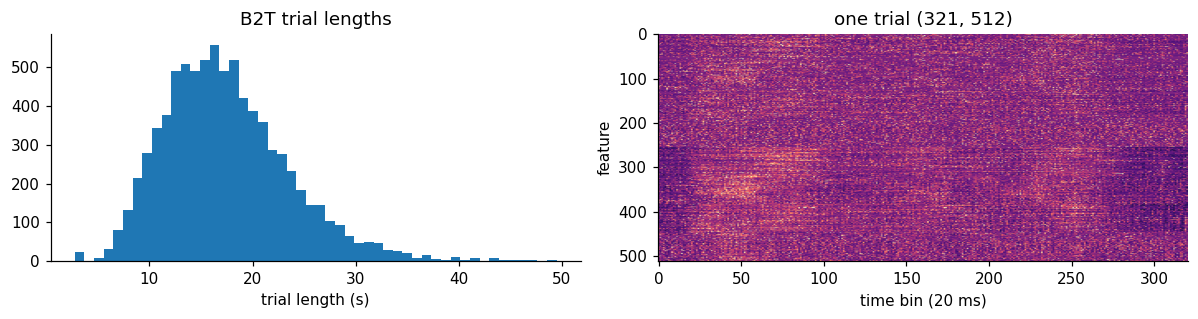

In [15]:
b2t = b2t_trial_table('train')
per_session = b2t.groupby('session').agg(n_trials=('trial', 'size'), minutes=('n_time_steps', lambda s: s.sum() * BIN_SIZE / 60))
print(len(b2t), 'train trials |', len(per_session), 'sessions |', f'{per_session.minutes.sum() / 60:.1f} h (train split)')

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].hist(b2t.n_time_steps * BIN_SIZE, bins=50); axes[0].set(xlabel='trial length (s)', title='B2T trial lengths')
x = load_b2t_trial(b2t.session.iloc[0], b2t.trial.iloc[0])
axes[1].imshow(x.T, aspect='auto', cmap='magma', vmax=np.percentile(x, 99))
axes[1].set(xlabel='time bin (20 ms)', ylabel='feature', title=f'one trial {x.shape}')
plt.tight_layout(); plt.show()

## 4. Dimensions side by side

In [16]:
pd.DataFrame({
    'IBL (1 probe)':   {'N per session': ibl['n_units'], 'N fixed across sessions': 'no (units differ)', 'session length': f"{np.ptp(ibl['spike_times']) / 60:.0f} min",
                        'structure': 'continuous + ~400 trials', 'labels': 'contrast, choice, feedback, movement'},
    'Allen (subset, 1 session)': {'N per session': allen['n_units'], 'N fixed across sessions': 'no (units differ)', 'session length': f"{allen_minutes:.0f} min kept (of ~160)",
                        'structure': 'continuous viewing epochs', 'labels': 'movie frame / spontaneous'},
    "B2T '25": {'N per session': 512, 'N fixed across sessions': 'yes (same arrays; drift across days)', 'session length': f"{per_session.minutes.median():.0f} min (train)",
                        'structure': 'trials ~17 s', 'labels': 'phonemes / sentence'},
}).T

,N per session,N fixed across sessions,session length,structure,labels
IBL (1 probe),39,no (units differ),64 min,continuous + ~400 trials,"contrast, choice, feedback, movement"
"Allen (subset, 1 session)",2766,no (units differ),51 min kept (of ~160),continuous viewing epochs,movie frame / spontaneous
B2T '25,512,yes (same arrays; drift across days),49 min (train),trials ~17 s,phonemes / sentence


## 5. How to pass them as input
- Mouse sessions: a different N per session, and no unit correspondence across sessions.
- B2T: a fixed 512 features. Its day-specific 512→512 layers only absorb drift.

**A. Binned + per-session read-in**: `[B, T, N_s]` windows → session-specific `Linear(N_s → d)` → shared `[B, T, d]` backbone input. Generalises the B2T day layers to variable N.

**B. Spike tokens (POYO-style)**: one token per spike `(unit_id, t)` with learned unit embeddings. No binning; sequence length = spike count.

In [17]:
def windows(X, T=100, stride=100):
    """[T_total, N] counts -> [B, T, N] float tensor (non-overlapping 2 s windows by default)."""
    v = np.lib.stride_tricks.sliding_window_view(X, T, axis=0)[::stride]  # [B, N, T]
    return torch.from_numpy(v.transpose(0, 2, 1).astype(np.float32))

xb = {'ibl': windows(X_ibl)[:8], 'allen': windows(X_allen)[:8]}
d_model = 256
readin = torch.nn.ModuleDict({k: torch.nn.Linear(v.shape[-1], d_model) for k, v in xb.items()})  # one per session
z = torch.cat([readin[k](v) for k, v in xb.items()])
for k, v in xb.items():
    print(f'{k:6s} window batch {tuple(v.shape)} -> read-in -> {tuple(readin[k](v).shape)}')
print('shared backbone input', tuple(z.shape))

ibl    window batch (8, 100, 39) -> read-in -> (8, 100, 256)
allen  window batch (8, 100, 2766) -> read-in -> (8, 100, 256)
shared backbone input (16, 100, 256)


In [18]:
# Option B cost: tokens per 2 s window = spikes per 2 s
for name, s, dur in [('ibl', ibl, np.ptp(ibl['spike_times'])), ('allen', allen, allen_minutes * 60)]:
    rate = len(s['spike_times']) / dur
    print(f'{name:6s} {rate * 2:,.0f} spike tokens per 2 s window  vs  {100 * s["n_units"]:,} binned cells')

ibl    424 spike tokens per 2 s window  vs  3,900 binned cells
allen  24,183 spike tokens per 2 s window  vs  276,600 binned cells


### Takeaways
- Variable N is the core issue → start with option A (per-session read-in + the shared backbone in `src/rnn_model.py`).
- IBL: many short, task-structured sessions, small N after QC.
- Allen: fewer, longer passive sessions, large N, and much looser QC than IBL.
- Allen spike tokens: tens of thousands per 2 s window → option B needs long context or unit subsampling.
- Open: keep non-good IBL units? Apply the stricter Allen metrics? Restrict Allen to visual cortex (`--allen_area_prefix VIS`)?